In [14]:
import numpy as np
import random
import matplotlib.pyplot as plt

In [15]:
maze = np.array([[0, 0, 0, 1],
                [1, 1, 0, 1],
                [0, 0, 0, 0],
                [0, 1, 1, 2]])

rows,cols=maze.shape
actions=[(-1,0),(1,0),(0,-1),(0,1)] # up, down, left, right

Q=np.zeros((rows,cols,4))
alpha,gamma,epsilon,episodes=0.1,0.9,0.2,1000


In [16]:
def step(state, a):
 r, c = state[0] + actions[a][0], state[1] + actions[a][1]
 if r < 0 or r >= rows or c < 0 or c >= cols or maze[r, c] == 1:
    return state, -5, False
 
 if maze[r, c] == 2:
    return (r, c), 100, True
 
 return (r, c), -1, False

In [17]:
for ep in range(episodes):
    state, done = (0, 0), False

    while not done:

        # Epsilon-greedy action selection
        if random.random() < epsilon:
            a = random.randint(0, 3)
        else:
            a = np.argmax(Q[state[0], state[1]])

        # Take action
        nxt, reward, done = step(state, a)

        # Q-learning update
        Q[state[0], state[1], a] += alpha * (
            reward + gamma * np.max(Q[nxt[0], nxt[1]])
            - Q[state[0], state[1], a]
        )

        # Update state
        state = nxt

In [ ]:
# Test the trained agent
state, path, done = (0, 0), [(0, 0)], False
while not done and len(path) < 30:
    a = np.argmax(Q[state[0], state[1]])
    state, _, done = step(state, a)
    path.append(state)
print("Path found by agent:", path)

Path found by agent: [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 3), (3, 3)]


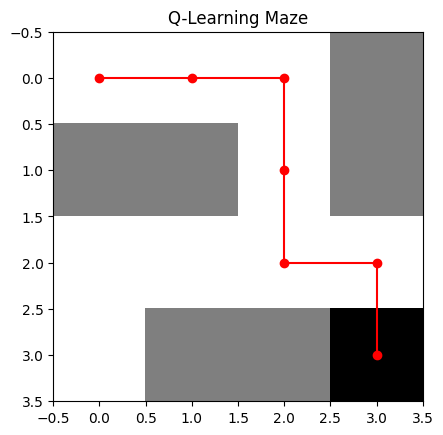

In [19]:
plt.imshow(maze, cmap="gray_r")
x = [p[1] for p in path]
y = [p[0] for p in path]
plt.plot(x, y, "ro-")
plt.title("Q-Learning Maze")
plt.show()